# Mapping Sexual Offence Trends in South Africa (2015/16–2024/25)

## 1. Introduction

This project analyses reported rape cases across South Africa using official South African Police Service (SAPS) crime statistics covering the 2015/16 to 2024/25 financial years.

The analysis explores national trends, provincial comparisons and police station-level patterns to identify changes in reported cases over time.

Python, particularly Pandas and Matplotlib, is used for data cleaning, analysis and visualisation.

### Project Objectives

- Examine national reported rape trends over ten financial years.
- Compare reported cases across South Africa's nine provinces.
- Identify changes in reported cases between 2015/16 and 2024/25.
- Identify the ten police stations with the highest reported counts in 2024/25.
- Explore historical trends among these ten stations.

In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Data Loading

The dataset was obtained from SAPS crime statistics and provided in Excel format. The RAW Data worksheet was imported into Python using Pandas for further inspection and analysis.

In [105]:
import os
os.getcwd()

'C:\\Users\\siphe\\Downloads\\South-Africa-Sexual-Offences-Analysis\\notebooks'

In [106]:
file_path = "../data/raw/SAPS_RAW_Data_Working_Copy.xlsx"

In [107]:
excel_file = pd.ExcelFile(file_path)
excel_file.sheet_names

['RAW Data', 'READ ME']

In [108]:
df = pd.read_excel(file_path, sheet_name="RAW Data")

In [109]:
df.head()

,Crime_Category National contribution placement,Crime_Category Provincial contribution placement,Comp level,Station Crime_Category,Station,District,Province,Crime_Category,Code,2015-2016,...,2021-2022,2022-2023,2023-2024,2024-2025,National contribution placement,National count diff placement,Provincial contribution placement,Provincial count diff placement,Count direction,Count offence group
0,Murder Station 618,Eastern Cape Murder Station 113,Station,Afsondering Murder,Afsondering,Alfred Nzo District,Eastern Cape,Murder,1,9.0,...,20.0,11.0,10.0,7.0,618.0,755.0,113.0,120.0,Decreased,17 Community reported serious crime
1,Attempted murder Station 941,Eastern Cape Attempted murder Station 139,Station,Afsondering Attempted murder,Afsondering,Alfred Nzo District,Eastern Cape,Attempted murder,2,5.0,...,5.0,6.0,0.0,1.0,941.0,424.0,139.0,67.0,Increased,17 Community reported serious crime
2,Robbery with aggravating circumstances Station...,Eastern Cape Robbery with aggravating circumst...,Station,Afsondering Robbery with aggravating circumsta...,Afsondering,Alfred Nzo District,Eastern Cape,Robbery with aggravating circumstances,4,13.0,...,6.0,8.0,2.0,0.0,1150.0,601.0,197.0,121.0,Decreased,17 Community reported serious crime
3,Common robbery Station 950,Eastern Cape Common robbery Station 149,Station,Afsondering Common robbery,Afsondering,Alfred Nzo District,Eastern Cape,Common robbery,6,0.0,...,0.0,0.0,0.0,1.0,950.0,406.0,149.0,67.0,Increased,17 Community reported serious crime
4,Rape Station 603,Eastern Cape Rape Station 95,Station,Afsondering Rape,Afsondering,Alfred Nzo District,Eastern Cape,Rape,9,22.0,...,15.0,17.0,16.0,20.0,603.0,244.0,95.0,33.0,Increased,Sexual offences


In [110]:
df.shape

(49482, 25)

In [111]:
df.columns.tolist()

['Crime_Category National contribution placement',
 'Crime_Category Provincial contribution placement',
 'Comp level',
 'Station Crime_Category',
 'Station',
 'District',
 'Province',
 'Crime_Category',
 'Code',
 '2015-2016',
 '2016-2017',
 '2017-2018',
 '2018-2019',
 '2019-2020',
 '2020-2021',
 '2021-2022',
 '2022-2023',
 '2023-2024',
 '2024-2025',
 'National contribution placement',
 'National count diff placement',
 'Provincial contribution placement',
 'Provincial count diff placement',
 'Count direction',
 'Count offence group']

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49482 entries, 0 to 49481
Data columns (total 25 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   Crime_Category National contribution placement    49481 non-null  object 
 1   Crime_Category Provincial contribution placement  49481 non-null  object 
 2   Comp level                                        49481 non-null  object 
 3   Station Crime_Category                            49481 non-null  object 
 4   Station                                           49481 non-null  object 
 5   District                                          49480 non-null  object 
 6   Province                                          49480 non-null  object 
 7   Crime_Category                                    48243 non-null  object 
 8   Code                                              48243 non-null  object 
 9   2015-2016        

## 3. Data Cleaning

The raw dataset was inspected to identify missing values, duplicate records and non-data rows.

Rows without a valid `Crime_Category` were removed because they contained report headings rather than actual crime records.

After cleaning, the dataset contained 48,243 rows and 25 columns, with no missing values or duplicate rows.

In [113]:
df.isnull().sum()

Crime_Category National contribution placement         1
Crime_Category Provincial contribution placement       1
Comp level                                             1
Station Crime_Category                                 1
Station                                                1
District                                               2
Province                                               2
Crime_Category                                      1239
Code                                                1239
2015-2016                                           1239
2016-2017                                           1239
2017-2018                                           1239
2018-2019                                           1239
2019-2020                                           1239
2020-2021                                           1239
2021-2022                                           1239
2022-2023                                           1239
2023-2024                      

In [114]:
missing_rows= df[df["Crime_Category"].isnull()]
missing_rows.head(10)

,Crime_Category National contribution placement,Crime_Category Provincial contribution placement,Comp level,Station Crime_Category,Station,District,Province,Crime_Category,Code,2015-2016,...,2021-2022,2022-2023,2023-2024,2024-2025,National contribution placement,National count diff placement,Provincial contribution placement,Provincial count diff placement,Count direction,Count offence group
48243,BAD PERFORMERS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48244,NaN,Station Name,Increased,Stabilzed,Decreased,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48245,Station,Nababeep,15,0,2,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48246,Station,Gans Bay,14,0,3,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48247,Station,Babanango,13,3,1,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48248,Station,Oranjeville,13,3,1,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48249,Station,Boons,13,3,1,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48250,Station,Philippolis,13,2,2,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48251,Station,Makapanstad,13,1,3,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
48252,Station,Kwanobuhle,13,1,3,Compare,50,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [115]:
df["Crime_Category"].notnull().sum()

np.int64(48243)

In [116]:
df.loc[df["Crime_Category"].isnull(), "2015-2016"].notnull().sum()

np.int64(0)

In [117]:
year_columns=[ "2015-2016", "2016-2017", "2017-2018", "2019-2020", "2020-2021", "2021-2022", "2022-2023", "2023-2024", "2024-2025"
            ]
df.loc[df["Crime_Category"].isnull(), year_columns].notnull().sum()
              

2015-2016    0
2016-2017    0
2017-2018    0
2019-2020    0
2020-2021    0
2021-2022    0
2022-2023    0
2023-2024    0
2024-2025    0
dtype: int64

In [118]:
df_clean= df[df["Crime_Category"].notnull()].copy()

In [119]:
df_clean.shape

(48243, 25)

In [120]:
df_clean.duplicated().sum()

np.int64(0)

In [121]:
df_clean.isnull().sum()

Crime_Category National contribution placement      0
Crime_Category Provincial contribution placement    0
Comp level                                          0
Station Crime_Category                              0
Station                                             0
District                                            0
Province                                            0
Crime_Category                                      0
Code                                                0
2015-2016                                           0
2016-2017                                           0
2017-2018                                           0
2018-2019                                           0
2019-2020                                           0
2020-2021                                           0
2021-2022                                           0
2022-2023                                           0
2023-2024                                           0
2024-2025                   

In [122]:
df_clean.to_csv("../data/cleaned.csv", index=False)

In [123]:
df_clean.to_csv("../data/cleaned/saps_cleaned.csv", index= False)

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was conducted to investigate reported rape cases at national, provincial and police station levels.

The analysis focuses on identifying patterns, comparing reported case counts and examining changes across the ten financial years.

In [124]:
df_rape= df_clean[df_clean["Crime_Category"]=="Rape"].copy()

In [125]:
df_rape.shape

(1237, 25)

In [126]:
year_columns= [ "2015-2016", "2016-2017", "2017-2018", "2018-2019", "2019-2020", "2020-2021", "2021-2022", "2022-2023", "2023-2024", "2024-2025"
              ]
rape_totals= df_rape[year_columns].sum()
rape_totals

2015-2016    166012.0
2016-2017    159312.0
2017-2018    160140.0
2018-2019    166332.0
2019-2020    169156.0
2020-2021    145320.0
2021-2022    166956.0
2022-2023    171120.0
2023-2024    170276.0
2024-2025    161900.0
dtype: float64

### 4.1 National Rape Trends

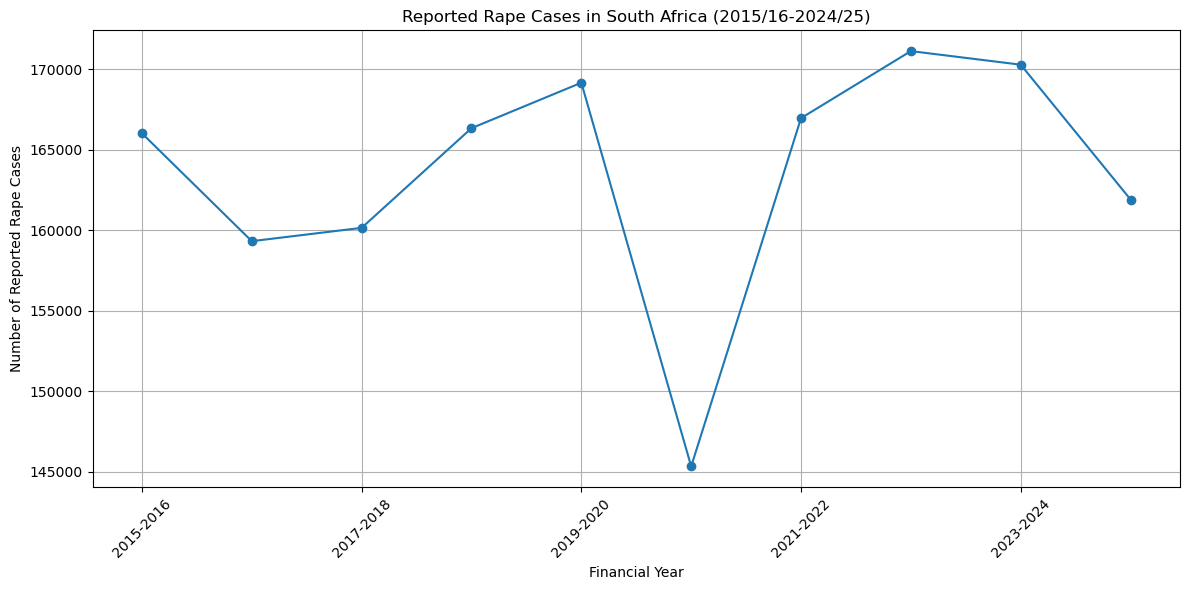

In [138]:
plt.figure(figsize=(12,6))
rape_totals.plot(kind="line", marker="o")

plt.title("Reported Rape Cases in South Africa (2015/16-2024/25)")
plt.xlabel("Financial Year")
plt.ylabel("Number of Reported Rape Cases")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()

plt.savefig("../visualisations/national_rape_trend.png",dpi=300, bbox_inches="tight")
plt.show()

In [139]:
province_totals= df_rape.groupby("Province")[year_columns].sum()
province_totals

,2015-2016,2016-2017,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025
Province,,,,,,,,,,
Eastern Cape,7437.0,6836.0,6821.0,7305.0,7282.0,6114.0,6969.0,6829.0,6787.0,6325.0
Free State,3059.0,2702.0,2573.0,2646.0,2936.0,2258.0,2595.0,2671.0,2841.0,2783.0
Gauteng,7605.0,7700.0,8062.0,8417.0,8509.0,7525.0,8675.0,8708.0,8648.0,8200.0
KwaZulu-Natal,7307.0,7032.0,7243.0,7667.0,8017.0,6685.0,7966.0,8433.0,8152.0,7855.0
Limpopo,3728.0,3317.0,3300.0,3501.0,3436.0,3126.0,3625.0,4021.0,4085.0,3726.0
Mpumalanga,2847.0,2712.0,2713.0,2903.0,2971.0,2611.0,3016.0,2772.0,2758.0,2894.0
National,41503.0,39828.0,40035.0,41583.0,42289.0,36330.0,41739.0,42780.0,42569.0,40475.0
North West,3433.0,3615.0,3479.0,3374.0,3136.0,2661.0,3098.0,3218.0,3343.0,3083.0
Northern Cape,1287.0,1143.0,1100.0,1121.0,1125.0,908.0,952.0,1099.0,1130.0,1045.0


In [ ]:
df_rape["Comp level"].value_counts(dropna=False)

In [ ]:
level_totals = df_rape.groupby("Comp level")[year_columns].sum()

level_totals

In [ ]:
df_rape_national= df_rape[df_rape["Comp level"]=="National"]
rape_totals= df_rape_national[year_columns].sum()
rape_totals

In [ ]:
df_rape_province = df_rape[df_rape["Comp level"]=="Province"].copy()

df_rape_province

In [ ]:
df_rape_province[df_rape_province["Province"] == "Western Cape"][["Province", "Comp level", "Crime_Category"] + year_columns]

In [ ]:
df_rape["Province"].unique()

In [ ]:
df_clean[
    (df_clean["Province"] == "Western Cape") &
    (df_clean["Comp level"] == "Province")
]

In [ ]:
df_rape_province[["Comp level", "Station", "Province", "Crime_Category"]]

In [ ]:
province_totals = df_rape_province.groupby("Station")[year_columns].sum()

province_totals

In [ ]:
province_latest = province_totals["2024-2025"].sort_values(ascending=False)

province_latest

### 4.2 Provincial Comparison (2024/25)

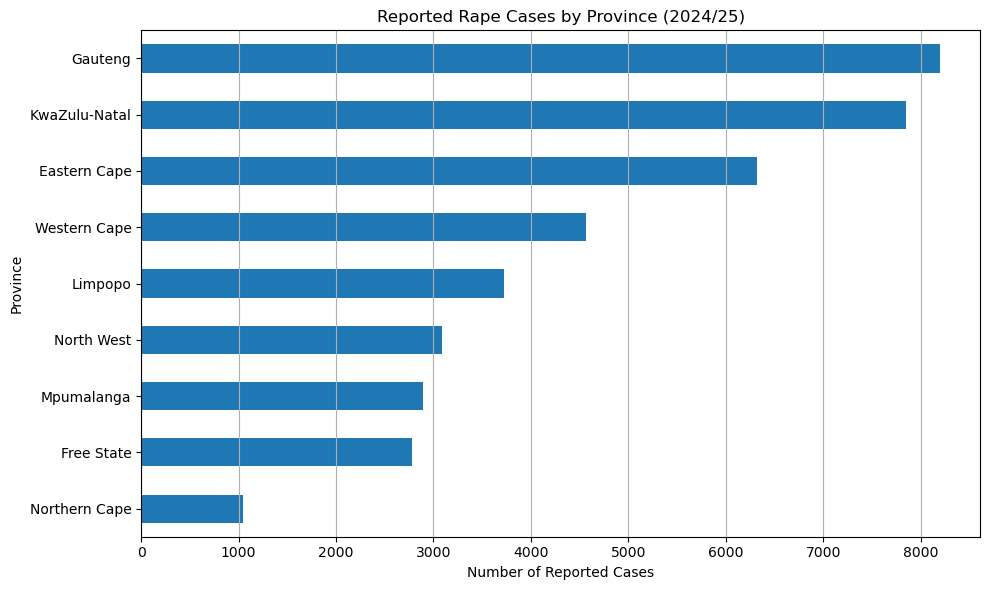

In [140]:
plt.figure(figsize=(10, 6))

province_latest.plot(kind="barh")

plt.title("Reported Rape Cases by Province (2024/25)")
plt.xlabel("Number of Reported Cases")
plt.ylabel("Province")

plt.gca().invert_yaxis()
plt.grid(axis="x")

plt.tight_layout()

plt.savefig("../visualisations/provincial_comparison_2024_25.png", dpi=300, bbox_inches="tight")
plt.show()

In [135]:
province_change = pd.DataFrame({
    "2015-2016": province_totals["2015-2016"],
    "2024-2025": province_totals["2024-2025"]
})

province_change["Change"] = (
    province_change["2024-2025"] - province_change["2015-2016"]
)

province_change["Percentage Change"] = (
    province_change["Change"] / province_change["2015-2016"] * 100
)

province_change = province_change.sort_values(
    "Percentage Change", ascending=False
)

province_change

,2015-2016,2024-2025,Change,Percentage Change
Station,,,,
Gauteng,7605.0,8200.0,595.0,7.823800
KwaZulu-Natal,7307.0,7855.0,548.0,7.499658
Mpumalanga,2847.0,2894.0,47.0,1.650861
Limpopo,3728.0,3726.0,-2.0,-0.053648
Western Cape,4800.0,4564.0,-236.0,-4.916667
Free State,3059.0,2783.0,-276.0,-9.022556
North West,3433.0,3083.0,-350.0,-10.195165
Eastern Cape,7437.0,6325.0,-1112.0,-14.952266
Northern Cape,1287.0,1045.0,-242.0,-18.803419


### 4.3 Provincial Percentage Changes

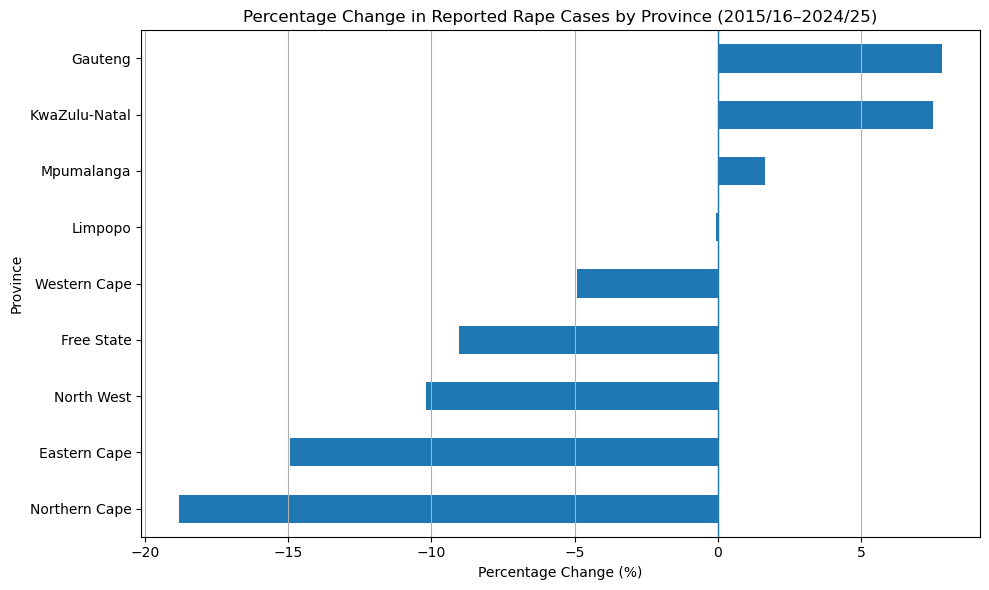

In [141]:
plt.figure(figsize=(10, 6))

province_change["Percentage Change"].sort_values().plot(kind="barh")

plt.title("Percentage Change in Reported Rape Cases by Province (2015/16–2024/25)")
plt.xlabel("Percentage Change (%)")
plt.ylabel("Province")

plt.axvline(x=0, linewidth=1)
plt.grid(axis="x")

plt.tight_layout()
plt.savefig("../visualisations/provincial_percentage_change.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.4 Provincial Trends Over Time

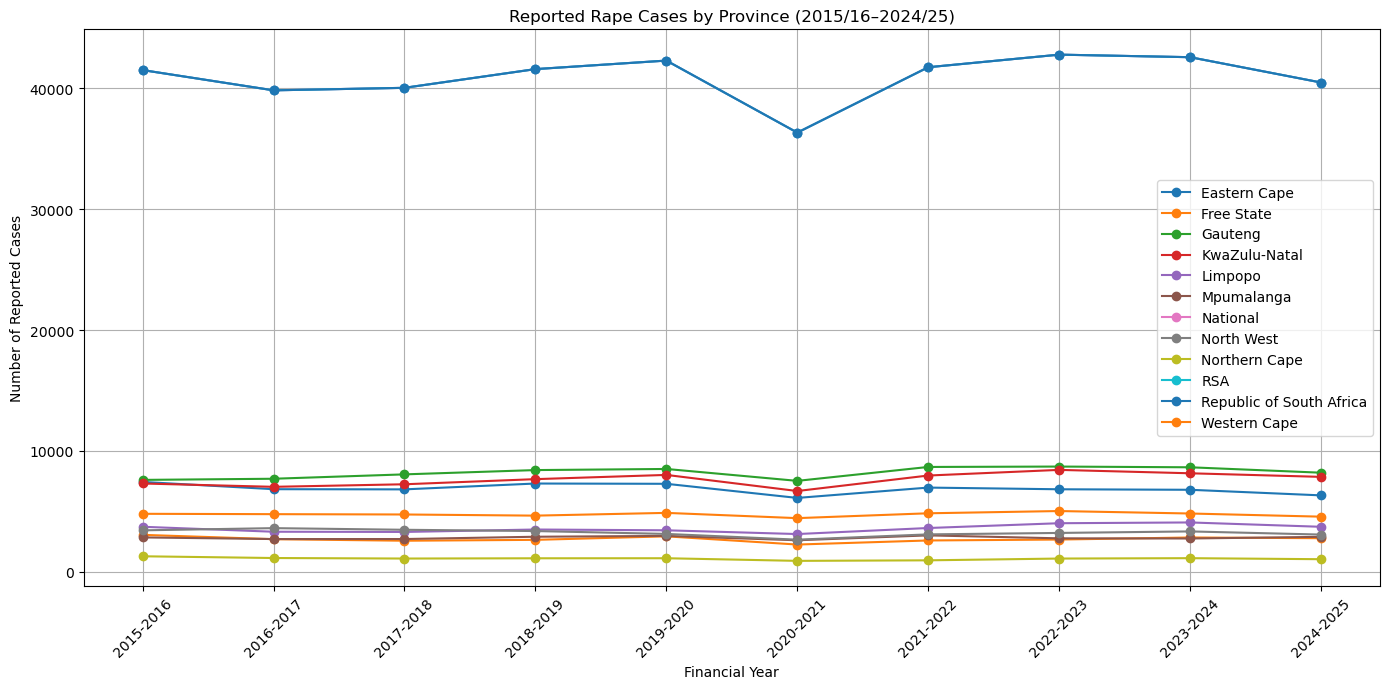

In [142]:
plt.figure(figsize=(14, 7))

for province in province_totals.index:
    plt.plot(year_columns, province_totals.loc[province], marker="o", label=province)

plt.title("Reported Rape Cases by Province (2015/16–2024/25)")
plt.xlabel("Financial Year")
plt.ylabel("Number of Reported Cases")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("../visualisations/provincial_trends_over_time.png",dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
df_rape_stations = df_rape[df_rape["Comp level"] == "Station"].copy()

df_rape_stations.shape

In [132]:
top10_stations = df_rape_stations.sort_values(
    by="2024-2025", ascending=False
)[["Station", "Province", "2024-2025"]].head(10)

top10_stations

,Station,Province,2024-2025
18763,Inanda,KwaZulu-Natal,302.0
27811,Thohoyandou,Limpopo,272.0
5815,Lusikisiki,Eastern Cape,252.0
19660,Umlazi,KwaZulu-Natal,251.0
5932,Mthatha,Eastern Cape,244.0
42085,Mfuleni,Western Cape,225.0
15058,Roodepoort,Gauteng,201.0
22624,Plessislaer,KwaZulu-Natal,200.0
9481,Bloemspruit,Free State,196.0
22429,Mountain Rise,KwaZulu-Natal,189.0


### 4.5 Top 10 Police Stations (2024/25)

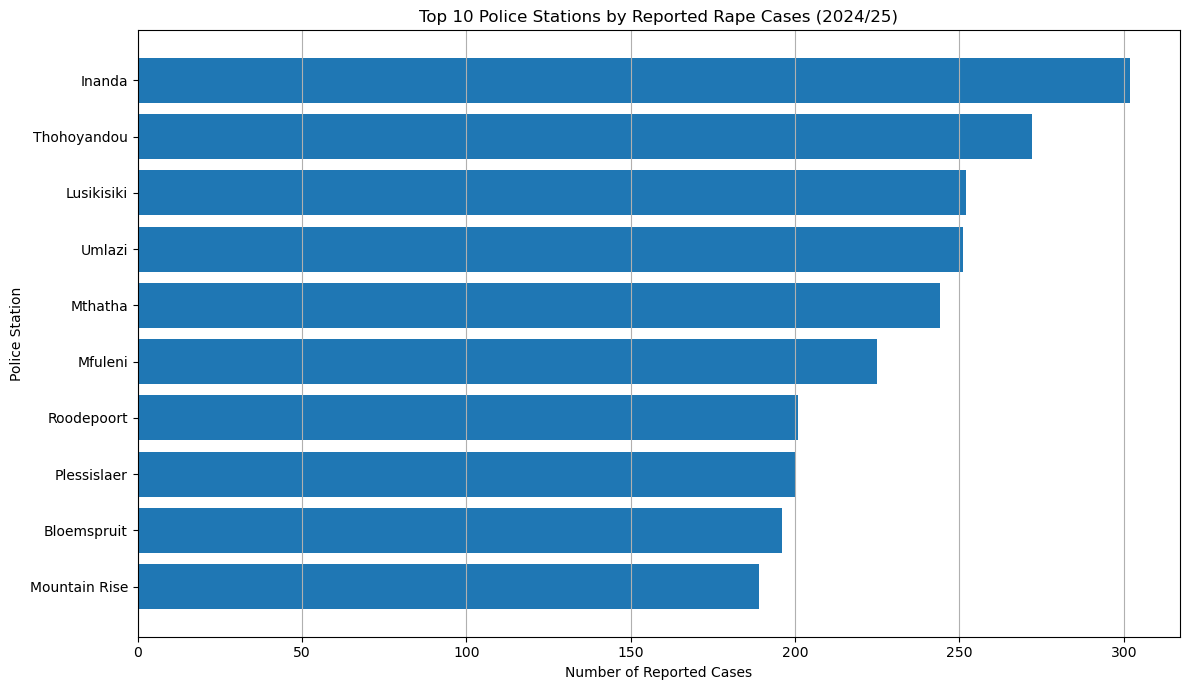

In [143]:
plt.figure(figsize=(12, 7))

top10_stations_sorted = top10_stations.sort_values("2024-2025")

plt.barh(top10_stations_sorted["Station"], top10_stations_sorted["2024-2025"])

plt.title("Top 10 Police Stations by Reported Rape Cases (2024/25)")
plt.xlabel("Number of Reported Cases")
plt.ylabel("Police Station")

plt.grid(axis="x")
plt.tight_layout()

plt.savefig("../visualisations/top10_police_stations_2024_25.png",dpi=300, bbox_inches="tight")
plt.show()

In [130]:
top10_names = top10_stations["Station"].tolist()

df_top10_trends = df_rape_stations[
    df_rape_stations["Station"].isin(top10_names)
].copy()

df_top10_trends[["Station", "Province"] + year_columns]

,Station,Province,2015-2016,2016-2017,2017-2018,2018-2019,2019-2020,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025
5815,Lusikisiki,Eastern Cape,138.0,139.0,191.0,280.0,191.0,228.0,328.0,287.0,239.0,252.0
5932,Mthatha,Eastern Cape,217.0,227.0,222.0,204.0,257.0,181.0,232.0,232.0,260.0,244.0
9481,Bloemspruit,Free State,195.0,132.0,152.0,157.0,181.0,129.0,158.0,160.0,211.0,196.0
15058,Roodepoort,Gauteng,80.0,65.0,79.0,85.0,135.0,74.0,87.0,99.0,135.0,201.0
18763,Inanda,KwaZulu-Natal,272.0,309.0,278.0,338.0,297.0,252.0,312.0,313.0,288.0,302.0
19660,Umlazi,KwaZulu-Natal,284.0,262.0,252.0,262.0,293.0,203.0,232.0,235.0,246.0,251.0
22429,Mountain Rise,KwaZulu-Natal,106.0,120.0,115.0,115.0,123.0,108.0,140.0,151.0,178.0,189.0
22624,Plessislaer,KwaZulu-Natal,234.0,179.0,177.0,179.0,236.0,159.0,180.0,194.0,155.0,200.0
27811,Thohoyandou,Limpopo,230.0,183.0,225.0,268.0,225.0,206.0,256.0,265.0,287.0,272.0
42085,Mfuleni,Western Cape,130.0,183.0,126.0,182.0,168.0,163.0,167.0,177.0,206.0,225.0


### 4.6 Trends Among the Top 10 Police Stations

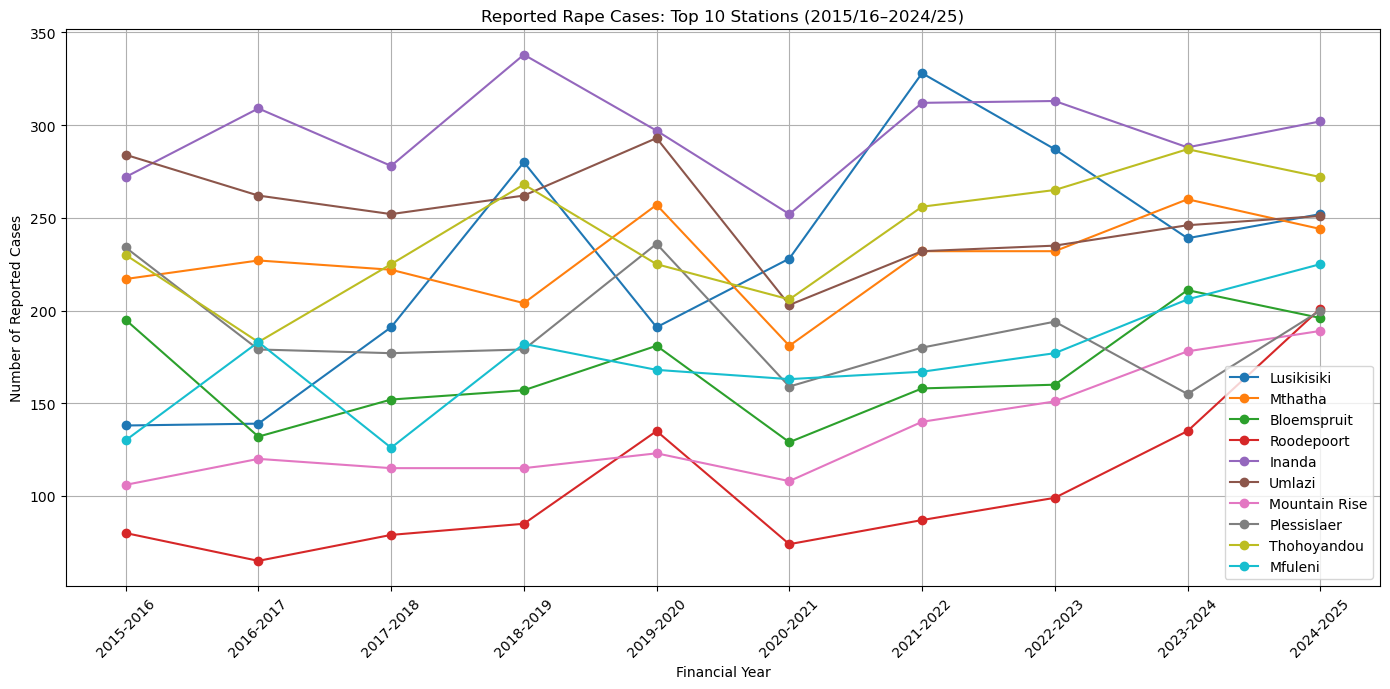

In [144]:
plt.figure(figsize=(14, 7))

for station in df_top10_trends["Station"]:
    station_data = df_top10_trends[df_top10_trends["Station"] == station]

    plt.plot(year_columns, station_data[year_columns].values.flatten(),
             marker="o", label=station)

plt.title("Reported Rape Cases: Top 10 Stations (2015/16–2024/25)")
plt.xlabel("Financial Year")
plt.ylabel("Number of Reported Cases")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig("../visualisations/top10_station_trends.png",dpi=300, bbox_inches="tight")
plt.show()

In [128]:
station_change = df_top10_trends[["Station", "Province", "2015-2016", "2024-2025"]].copy()

station_change["Change"] = (
    station_change["2024-2025"] - station_change["2015-2016"]
)

station_change["Percentage Change"] = (
    station_change["Change"] / station_change["2015-2016"] * 100
)

station_change = station_change.sort_values("Percentage Change", ascending=False)

station_change

,Station,Province,2015-2016,2024-2025,Change,Percentage Change
15058,Roodepoort,Gauteng,80.0,201.0,121.0,151.250000
5815,Lusikisiki,Eastern Cape,138.0,252.0,114.0,82.608696
22429,Mountain Rise,KwaZulu-Natal,106.0,189.0,83.0,78.301887
42085,Mfuleni,Western Cape,130.0,225.0,95.0,73.076923
27811,Thohoyandou,Limpopo,230.0,272.0,42.0,18.260870
5932,Mthatha,Eastern Cape,217.0,244.0,27.0,12.442396
18763,Inanda,KwaZulu-Natal,272.0,302.0,30.0,11.029412
9481,Bloemspruit,Free State,195.0,196.0,1.0,0.512821
19660,Umlazi,KwaZulu-Natal,284.0,251.0,-33.0,-11.619718
22624,Plessislaer,KwaZulu-Natal,234.0,200.0,-34.0,-14.529915


## Methodology

The analysis was conducted using Python, with Pandas for data manipulation and Matplotlib for data visualisation.

The following steps were followed:

1. Imported the SAPS crime statistics Excel workbook into Python.
2. Inspected the dataset and removed rows without a valid crime category.
3. Filtered the cleaned dataset to focus on the crime category "Rape".
4. Separated national, provincial and police station records using the `Comp level` column to avoid double-counting aggregated figures.
5. Compared reported rape cases across ten financial years, from 2015/16 to 2024/25.
6. Calculated absolute and percentage changes between 2015/16 and 2024/25.
7. Created visualisations to communicate the findings.

## Limitations

- The dataset represents reported rape cases and does not capture all incidents that may have occurred.
- The analysis uses reported case counts rather than population-adjusted rates.
- Changes in reported cases do not necessarily reflect changes in the actual occurrence of rape.
- The analysis does not establish the causes behind increases or decreases.
- The top 10 police stations were selected based on their reported case counts in 2024/25, so they do not represent all stations with increasing trends.

# Key Findings

## 1. National Trend

- Reported rape cases reached their highest level during the period in 2022/23, with 42,780 cases.
- The lowest figure was recorded in 2020/21, with 36,330 cases.
- In 2024/25, 40,475 rape cases were reported, showing a decrease from the 2022/23 peak.

## 2. Provincial Comparison (2024/25)

- Gauteng recorded the highest number of reported rape cases, with 8,200.
- KwaZulu-Natal followed with 7,855 cases.
- The Eastern Cape recorded 6,325 cases.
- The Northern Cape recorded the lowest number, with 1,045 cases.
- The provincial figures represent reported case counts and should not be interpreted as population-adjusted crime rates.

## 3. Changes in Reported Rape Cases by Province (2015/16–2024/25)

- Gauteng recorded an increase of 7.82%.
- KwaZulu-Natal recorded an increase of 7.50%.
- Mpumalanga recorded a slight increase of 1.65%.
- The Northern Cape recorded the largest percentage decrease, at 18.80%.
- The Eastern Cape recorded the largest absolute decrease, with 1,112 fewer reported cases.

## 4. Police Station Analysis (2024/25)

- Inanda Police Station in KwaZulu-Natal recorded the highest number of reported rape cases, with 302.
- Thohoyandou in Limpopo followed with 272 cases.
- Lusikisiki in the Eastern Cape recorded 252 cases.
- Five of the ten stations with the highest reported counts were in KwaZulu-Natal.
- These figures identify stations with the highest reported counts, not necessarily the highest rates of rape.

## 5. Changes in Reported Cases Among the Top 10 Stations (2015/16–2024/25)

- Roodepoort recorded the largest percentage increase among the selected stations, rising by 151.25%.
- Lusikisiki recorded the second-largest percentage increase, at 82.61%.
- Mountain Rise and Mfuleni also experienced substantial increases of 78.30% and 73.08%, respectively.
- Umlazi and Plessislaer were the only two stations in this group to record decreases, at 11.62% and 14.53%, respectively.
- These comparisons are limited to the ten stations selected based on their 2024/25 reported case counts.

## 6. Conclusion

This analysis examined reported rape cases across South Africa from 2015/16 to 2024/25 using SAPS crime statistics.

The findings show that reported rape cases fluctuated over the ten-year period, reaching their lowest level in 2020/21 before increasing in subsequent years. By 2024/25, the national figure stood at 40,475 reported cases.

At provincial level, Gauteng and KwaZulu-Natal consistently recorded some of the highest numbers of reported cases. However, changes over time varied across provinces. The police station analysis also highlighted differences in reported case counts and trends among the ten stations with the highest figures in 2024/25.

Overall, the analysis demonstrates how Python and data visualisation can be used to explore crime statistics, identify patterns and communicate findings.

It is important to recognise that these figures represent reported cases rather than the total number of incidents. The analysis also uses raw counts rather than population-adjusted rates, meaning that the results should not be interpreted as direct measures of individual risk.